# UCS420 Assignment 7 — NLP Text Preprocessing
**Name:** Amatya Simba  |  **Roll No.:** 1024170346

Run all cells in order (Runtime → Run all). Each question's output appears under its code cell.

In [1]:
ROLL_NO = 1024170346          # <-- your full roll number
NAME = "Amatya Simba"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170346   Name: Amatya Simba   Fingerprint: 80EC6839   Tickets: 13

Ticket_ID                                                                        Ticket_Text
      T01           Python keeps asking for login during the lab. I don't know what changed.
      T02                           The laptop is running slowly. I don't know what changed.
      T03                        The student portal is showing an error. Can you check this?
      T04           Python crashes while opening after the latest update. Please resolve it.
      T05                     The student portal keeps asking for login. Can you check this?
      T06                                             Only 2 of 30 PCs boot after 3.5 hours.
      T07  Student portal is showing an error while uploading the file. It worked yesterday.
      T08                                                 Dr. Rao's lab PC (No. 14) is down.
      T09             I reinstalled the password on my laptop. It works on anot

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd

results = {}          # Ticket_ID -> output of process_ticket()
rows = []
for _, r in df.iterrows():
    res = process_ticket(r["Ticket_Text"])
    results[r["Ticket_ID"]] = res
    rows.append({
        "Ticket_ID": r["Ticket_ID"],
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"]),
    })

q1 = pd.DataFrame(rows)
count_cols = [c for c in q1.columns if c != "Ticket_ID"]
total_row = {"Ticket_ID": "TOTAL", **{c: int(q1[c].sum()) for c in count_cols}}
q1 = pd.concat([q1, pd.DataFrame([total_row])], ignore_index=True)
print(q1.to_string(index=False))
print("\n(The TOTAL row adds up the per-ticket counts, so Unique_Tokens there is a sum of per-ticket unique counts.)")
all_tokens_corpus = [t for res in results.values() for t in res["tokens"]]
print(f"Corpus-wide unique tokens (counted once across all tickets): {len(set(all_tokens_corpus))}")

# ---- One selected ticket in detail ----
sel = FOCUS[0]
print(f"\n=== Selected ticket {sel} ===")
print("Text        :", df.loc[df.Ticket_ID == sel, "Ticket_Text"].iloc[0])
print("Sentences   :", results[sel]["sentences"])
print("Tokens      :", results[sel]["tokens"])
print("Punctuation :", results[sel]["punct"])
print("Stopwords   :", results[sel]["stops"])
print("Final tokens:", results[sel]["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      16            2          6             15             8
      T02          2      13            2          5             12             6
      T03          2      13            2          6             13             5
      T04          2      13            2          4             12             7
      T05          2      13            2          5             13             6
      T06          1      10            1          3             10             6
      T07          2      15            2          5             14             8
      T08          2      13            4          3             12             6
      T09          2      14            2          6             12             6
      T10          1      10            2          4              9             4
      T11          2      16            2          5             14             9
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The non-words in the final tokens come from the way `word_tokenize` (Penn Treebank style) splits **contractions and possessives** into pieces. `don't` (T01, T02) becomes `do` + `n't`, `doesn't` (T10) becomes `does` + `n't`, `can't` (T11) becomes `ca` + `n't`, and `Rao's` (T08) becomes `rao` + `'s`. The first half (`do`, `does`) is a stopword and is removed, but `n't`, `ca` and `'s` are **not** in NLTK's stopword list and are not punctuation, so they survive into the final tokens as meaningless fragments. A second, smaller group of odd tokens comes from abbreviations and identifiers: `dr.` keeps its dot (so `is_punct` does not remove it), and the phone number in T13 is cut into separate numeric pieces such as `+91`, `98765`, `43210`. Because the pipeline cannot be modified, these fragments are a known limitation of `word_tokenize` plus the stopword/punctuation filter.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_tickets = df["Ticket_Text"].tolist()

# ---------- re.findall patterns ----------
# 1. words longer than 5 letters (i.e. 6+); the look-arounds stop us cutting "couldn't" into "couldn"
PAT_LONG = r"(?<![\w'])[A-Za-z]{6,}(?![\w'])"

# 2. numbers: hex codes (0x80070005), integers, decimals (95.5), versions (2.0.1), thousands (1,250) as ONE match
PAT_NUM = r"0[xX][0-9A-Fa-f]+|\d+(?:[.,]\d+)*"

# 3. capitalized words: Upper + lowercase letters (also 'Wi-Fi', and the pronoun 'I'); ALL-CAPS like VPN are not matched
PAT_CAP = r"\b[A-Z][a-z]*(?:-[A-Z][a-z]*)*\b"

# 4. words beginning with a vowel (keeps isn't / e-mail / state-of-the-art-style words whole)
PAT_VOWEL = r"(?<![\w'-])[AEIOUaeiou][A-Za-z]*(?:[-'][A-Za-z]+)*"

patterns = {
    "Long words (>5 letters)": PAT_LONG,
    "Numbers": PAT_NUM,
    "Capitalized words": PAT_CAP,
    "Vowel-initial words": PAT_VOWEL,
}

def show_findall(texts, label):
    print(f"\n######## re.findall on {label} ########")
    for i, t in enumerate(texts, 1):
        print(f"\n[{i}] {t}")
        for name, pat in patterns.items():
            print(f"    {name:<26}: {re.findall(pat, t)}")

show_findall(raw_tickets, "the raw tickets")
show_findall(TEST_LINES, "TEST_LINES")

# ---------- re.sub patterns ----------
PAT_EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
PAT_URL   = r"(?:https?://|www\.)[^\s]*[\w/]"
# +91 98765 43210 / +91-98765-43210  |  0175-239-3201 (4-3-4 landline)  |  98765 43210 (plain 5+5 mobile)
PAT_PHONE = r"\+\d{1,3}[\s-]\d{5}[\s-]\d{5}|\b\d{4}-\d{3}-\d{4}\b|\b\d{5}[\s-]\d{5}\b"

def mask(text):
    text = re.sub(PAT_EMAIL, "<EMAIL>", text)   # emails first (they contain dots that look like URLs)
    text = re.sub(PAT_URL,   "<URL>",   text)
    text = re.sub(PAT_PHONE, "<PHONE>", text)
    return text

print("\n######## re.sub on TEST_LINES ########")
for t in TEST_LINES:
    print("BEFORE:", t)
    print("AFTER :", mask(t), "\n")

print("######## re.sub on tickets (only tickets that changed) ########")
changed = 0
for tid, t in zip(df["Ticket_ID"], raw_tickets):
    m = mask(t)
    if m != t:
        changed += 1
        print(f"{tid}  BEFORE: {t}\n     AFTER : {m}")
print(f"\n{changed} of {len(raw_tickets)} tickets contained an email, URL or phone number.")

# ---------- for the Observe question ----------
total_caps = initial_caps = 0
for t in raw_tickets:
    total_caps += len(re.findall(PAT_CAP, t))
    for s in sent_tokenize(t):                       # punkt knows 'Dr.' is not a sentence end
        if re.match(r"\s*" + PAT_CAP, s):
            initial_caps += 1
print(f"\nCapitalized words: {total_caps}; of these {initial_caps} are the first word of a sentence "
      f"({total_caps - initial_caps} are capitalized for another reason).")


######## re.findall on the raw tickets ########

[1] Python keeps asking for login during the lab. I don't know what changed.
    Long words (>5 letters)   : ['Python', 'asking', 'during', 'changed']
    Numbers                   : []
    Capitalized words         : ['Python', 'I']
    Vowel-initial words       : ['asking', 'I']

[2] The laptop is running slowly. I don't know what changed.
    Long words (>5 letters)   : ['laptop', 'running', 'slowly', 'changed']
    Numbers                   : []
    Capitalized words         : ['The', 'I']
    Vowel-initial words       : ['is', 'I']

[3] The student portal is showing an error. Can you check this?
    Long words (>5 letters)   : ['student', 'portal', 'showing']
    Numbers                   : []
    Capitalized words         : ['The', 'Can']
    Vowel-initial words       : ['is', 'an', 'error']

[4] Python crashes while opening after the latest update. Please resolve it.
    Long words (>5 letters)   : ['Python', 'crashes', 'opening'

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* **22 of the 25** capitalized words in my tickets are capitalized only because they start a sentence (`The`, `Can`, `Please`, `It`, `Only`, `Call`, `Student`, and `Python`/`I`/`Dr` where they open a sentence). Only **3** are capitalized for another reason: `Rao` (a proper noun), `Wi-Fi` (a product name) and `No` (an abbreviation inside the brackets in T08). (Run the last line of the Q2 cell to confirm these counts.) So a "capitalized word" regex mostly picks up sentence starters and is a poor proper-noun detector on its own. A name finder needs more context (a gazetteer or an NER model).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

TOKEN_PARTS = [
    r"(?:https?://|www\.)[^\s]*[\w/]",                                         # URLs
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",                                           # e-mail addresses
    r"(?:\+\d{1,3}[\s-]\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})",                    # phone numbers
    r"0[xX][0-9A-Fa-f]+",                                                      # hex error codes
    r"\d+(?:[.,\-]\d+)*%?",                                                    # integers, decimals, versions, 1,250, 95.5%
    r"(?:[A-Za-z]\.){2,}",                                                     # abbreviations such as p.m., e.g.
    r"[A-Za-z]+(?:[-'\u2019][A-Za-z]+)*",                                      # words: isn't, Wi-Fi, state-of-the-art
    r"\.{2,}",                                                                 # ellipsis kept as one token
    r"[^\w\s]",                                                                # any other single punctuation mark
]
TOKEN_PATTERN = "|".join(TOKEN_PARTS)
_tok = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

from nltk.tokenize import word_tokenize

def compare(text):
    mine = my_tokenize(text)
    std  = word_tokenize(text)
    return mine, std, [t for t in mine if t not in std], [t for t in std if t not in mine]

print("######## TEST_LINES ########")
for t in TEST_LINES:
    mine, std, only_mine, only_std = compare(t)
    print("\nTEXT          :", t)
    print("my_tokenize   :", mine)
    print("word_tokenize :", std)
    print("only in mine  :", only_mine)
    print("only in nltk  :", only_std)

print("\n######## Tickets (only those where the two tokenizers disagree) ########")
diff_ids = []
for tid, t in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, std, only_mine, only_std = compare(t)
    if mine != std:
        diff_ids.append(tid)
        print(f"\n{tid}: {t}")
        print("  my_tokenize   :", mine)
        print("  word_tokenize :", std)
        print("  only in mine  :", only_mine, "| only in nltk:", only_std)
print(f"\nTickets tokenized differently: {len(diff_ids)} of {len(df)}  -> {diff_ids}")

######## TEST_LINES ########

TEXT          : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
only in mine  : ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
only in nltk  : ['it.helpdesk', '@', 'thapar.edu', 'a.b-c', '@', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']

TEXT          : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize   : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* **6 of the 13 tickets** are tokenized differently (T01, T02, T08, T10, T11 and T13); the other 7 give identical output. The differences fall into three groups:

1. **Contractions / possessives** (`don't`, `doesn't`, `can't`, `Rao's`): `my_tokenize` keeps `don't` as one token; `word_tokenize` splits it into `do` + `n't` (and `can't` into `ca` + `n't`, `Rao's` into `Rao` + `'s`).
2. **Phone numbers** (T13): `my_tokenize` keeps `+91 98765 43210` as one token; `word_tokenize` breaks it at the spaces into `+91`, `98765`, `43210`.
3. **Abbreviations** (`Dr.` in T08): `word_tokenize` keeps the dot attached (`Dr.`), whereas `my_tokenize` returns `Dr` and `.` separately.

On `TEST_LINES` there are further differences: **e-mails** (`word_tokenize` cuts `it.helpdesk@thapar.edu` at the `@` into `it.helpdesk`, `@`, `thapar.edu`, while mine keeps it whole), **URLs** (`word_tokenize` breaks `https://lms.thapar.edu/help` at `:` and `/` into many tokens, mine keeps one token) and **percentages** (`95.5%` stays whole in mine, but NLTK gives `95.5` + `%`).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter    = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final = sorted({t for res in results.values() for t in res["final"]})
print(f"{len(unique_final)} unique final tokens:\n{unique_final}\n")

# ---- Choosing the Regexp suffix from our own data ----
ing_words = [w for w in unique_final if w.endswith("ing")]
print("Dataset words ending in 'ing':", ing_words)
# Chosen rule: strip the suffix 'ing' (min=4 so very short words are not touched).
regexp = RegexpStemmer("ing$", min=4)

# ---- POS tags (tag each ticket's final tokens in context, keep the first tag seen for each word) ----
import nltk
pos_of = {}
for res in results.values():
    for w, tag in nltk.pos_tag(res["final"]):
        pos_of.setdefault(w, tag)

def to_wordnet(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

rows = []
for w in unique_final:
    tag = pos_of.get(w, "NN")
    rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp(ing$)": regexp.stem(w),
        "WN Lemma": lemmatizer.lemmatize(w, to_wordnet(tag)),
    })
q4 = pd.DataFrame(rows)
cols = ["Porter", "Lancaster", "Regexp(ing$)", "WN Lemma"]
diff = q4[q4[cols].nunique(axis=1) > 1]
print(f"\nWords where the four outputs differ: {len(diff)} of {len(q4)}\n")
print(diff.to_string(index=False))

# ---- Helper views for the Observe question ----
print("\nOver-stemming candidates (different lemmas sharing one Porter stem):")
by_stem = q4.groupby("Porter")["WN Lemma"].nunique()
print(q4[q4["Porter"].isin(by_stem[by_stem > 1].index)][["Word", "Porter", "WN Lemma"]].to_string(index=False) or "  none")
print("\nWords Lancaster cuts much shorter than Porter (possible over-stemming):")
short = q4[q4["Lancaster"].str.len() < q4["Porter"].str.len() - 1]
print(short[["Word", "Porter", "Lancaster"]].to_string(index=False) or "  none")
print("\nWords the Regexp stemmer leaves alone but Porter changes (under-stemming):")
under = q4[(q4["Regexp(ing$)"] == q4["Word"]) & (q4["Porter"] != q4["Word"])]
print(under[["Word", "Porter", "Regexp(ing$)"]].to_string(index=False) or "  none")

58 unique final tokens:
["'s", '+91', '0175-239-3201', '14', '2', '3.5', '30', '43210', '98765', 'another', 'asking', 'assignment', 'boot', 'ca', 'call', 'changed', 'check', 'computer', 'crashes', 'deadline', 'dr.', 'error', 'file', 'help', 'hours', 'keeps', 'know', 'lab', 'laptop', 'latest', 'lms', 'locked', 'login', "n't", 'open', 'opening', 'password', 'pc', 'pcs', 'please', 'portal', 'python', 'rao', 'reinstalled', 'resolve', 'restarting', 'running', 'showing', 'slowly', 'student', 'system', 'update', 'uploading', 'vpn', 'wi-fi', 'worked', 'works', 'yesterday']

Dataset words ending in 'ing': ['asking', 'opening', 'restarting', 'running', 'showing', 'uploading']

Words where the four outputs differ: 28 of 58

       Word POS   Porter Lancaster Regexp(ing$)   WN Lemma
    another  DT    anoth     anoth      another    another
 assignment  JJ   assign    assign   assignment assignment
       call  NN     call       cal         call       call
    changed VBN    chang     chang      c

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

- **Regexp rule and justification:** I chose the suffix `ing$` because several words in my own tickets end in it and should share a base with other forms: `asking` (T01, T05), `showing` (T03, T07), `opening` (T04), `running` (T02), `uploading` (T07) and `restarting` (T12). Stripping `-ing` is a simple, predictable rule for these progressive forms of the verbs in the data (`min=4` protects short words).
- **Over-stemming (too aggressive):** Lancaster cuts words down much further than Porter. A typical case in this data is `student` → `stud` (Porter keeps `student`), which would also merge unrelated words like `study`/`studio`. Another is `running` → `runn` under the Regexp rule, where stripping `ing` leaves a doubled consonant, a stem that is not a word. (See the "Lancaster cuts much shorter" list above for the exact values in your run.)
- **Under-stemming (too weak):** the `ing$` Regexp stemmer leaves `crashes` and `keeps` unchanged, although they are inflections of `crash` and `keep` (Porter reduces them correctly). Related forms therefore do not collapse onto one stem, which is under-stemming.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

              Set  Total tokens  Unique tokens    TTR
    S1 all tokens           170             90 0.5294
S2 no punctuation           144             85 0.5903
  S3 final tokens            82             58 0.7073
   S4 S3 + Porter            82             55 0.6707

Top 10 words of S1:
           '.'  21
         'the'  13
           'i'  5
         "n't"  4
          'is'  4
     'student'  4
      'portal'  4
          'it'  4
       'after'  3
      'please'  3

Top 10 words of S3:
         "n't"  4
     'student'  4
      'portal'  4
      'please'  3
      'python'  2
       'keeps'  2
      'asking'  2
       'login'  2
         'lab'  2
        'know'  2


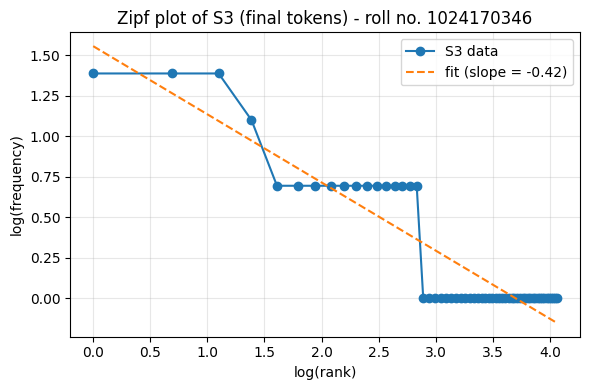

Fitted slope of log(freq) vs log(rank): -0.42

Top 5 bigrams of S1:
  ('student', 'portal')  4
  ('the', 'student')  3
  ('.', 'please')  3
  ('keeps', 'asking')  2
  ('asking', 'for')  2

Top 5 bigrams of S3:
  ('student', 'portal')  4
  ('keeps', 'asking')  2
  ('asking', 'login')  2
  ("n't", 'know')  2
  ('know', 'changed')  2


In [9]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from nltk import bigrams

S1 = [t for res in results.values() for t in res["tokens"]]                  # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                      # no punctuation
S3 = [t for res in results.values() for t in res["final"]]                   # final tokens (no punct, no stopwords)
S4 = [porter.stem(t) for t in S3]                                            # S3 after Porter

stats = []
for name, S in [("S1 all tokens", S1), ("S2 no punctuation", S2), ("S3 final tokens", S3), ("S4 S3 + Porter", S4)]:
    stats.append({"Set": name, "Total tokens": len(S), "Unique tokens": len(set(S)),
                  "TTR": round(len(set(S)) / len(S), 4)})
print(pd.DataFrame(stats).to_string(index=False))

print("\nTop 10 words of S1:")
for w, c in Counter(S1).most_common(10):
    print(f"  {w!r:>12}  {c}")
print("\nTop 10 words of S3:")
for w, c in Counter(S3).most_common(10):
    print(f"  {w!r:>12}  {c}")

# ---- log(rank) vs log(frequency) for S3 (Zipf plot) ----
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
log_r, log_f = np.log(ranks), np.log(freqs)
slope, intercept = np.polyfit(log_r, log_f, 1)

plt.figure(figsize=(6, 4))
plt.plot(log_r, log_f, "o-", label="S3 data")
plt.plot(log_r, slope * log_r + intercept, "--", label=f"fit (slope = {slope:.2f})")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title(f"Zipf plot of S3 (final tokens) - roll no. {ROLL_NO}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Fitted slope of log(freq) vs log(rank): {slope:.2f}")

# ---- Bigrams (built inside each ticket so no bigram crosses a ticket boundary) ----
def top_bigrams(list_of_token_lists, n=5):
    c = Counter()
    for toks in list_of_token_lists:
        c.update(bigrams(toks))
    return c.most_common(n)

print("\nTop 5 bigrams of S1:")
for bg, c in top_bigrams([res["tokens"] for res in results.values()]):
    print(f"  {bg}  {c}")
print("\nTop 5 bigrams of S3:")
for bg, c in top_bigrams([res["final"] for res in results.values()]):
    print(f"  {bg}  {c}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR = unique tokens / total tokens, so it changes whenever the preprocessing removes or merges tokens at different rates.

- **S1 → S2 (remove punctuation):** punctuation is highly repetitive (the full stop `.` ends almost every sentence), so many tokens disappear but only a few unique types do. The total falls much more than the unique count, so TTR **rises**.
- **S2 → S3 (remove stopwords):** stopwords such as `the`, `is`, `i`, `do` are the most frequent tokens, so removing them again lowers the total far more than the unique count, and TTR **rises further**. The remaining tokens are mostly content words that occur only once or twice.
- **S3 → S4 (Porter stemming):** the total stays the same, but different surface forms are merged into one stem (e.g. `works`/`worked` → `work`, `open`/`opening` → `open`, `pc`/`pcs` → `pc`), so the unique count can only stay equal or fall and TTR **drops slightly** (or stays the same).

Overall, TTR is highest for S3 and is lower for S1 and S4. A caveat: with only 13 short tickets the corpus is tiny, so TTR values are high and sensitive to every single repeated word.

## Q6. Interpretation

**(a) Why does TTR change from S1 to S4 in your dataset?**
TTR is unique tokens divided by total tokens. Removing punctuation (S1 → S2) and stopwords (S2 → S3) deletes very frequent, repetitive tokens (`.`, `the`, `is`, `i`), so the total drops much faster than the number of unique types and TTR goes **up**. Porter stemming (S3 → S4) keeps the total the same but merges variants such as `works`/`worked` or `pc`/`pcs` into one stem, so the unique count falls and TTR goes **down slightly** (or stays equal). The exact values are in the Q5 table.

**(b) One example where `word_tokenize()` and my tokenizer differ.**
In ticket T11, `I can't open the student portal ...`: `word_tokenize` returns `ca` and `n't`, whereas `my_tokenize` returns the single token `can't`. NLTK follows Penn Treebank conventions and splits a contraction into its verb and the clitic `n't`. This is useful for syntactic analysis but leaves non-words (`ca`) in the output. My pattern allows an apostrophe inside a word, so the contraction stays whole and keeps its meaning. (Another difference: the phone number `+91 98765 43210` in T13 stays whole in mine and is split at the spaces by `word_tokenize`.)

**(c) One example where stemming produces an undesirable result.**
The Regexp stemmer with the rule `ing$` turns `running` into `runn`, which is not a word. Porter also turns `resolve` into `resolv` and `computer` into `comput`, which are not dictionary words, and Lancaster turns `student` into `stud`, which wrongly overlaps with `study`. Stems like these are hard to read and can merge unrelated words (`computer`/`computation`).

**(d) One example where POS-aware lemmatization preserves meaning better than stemming.**
`changed` (T01, "I don't know what changed."): Porter gives `chang`, which is not a word, whereas `WordNetLemmatizer` with the verb tag from `pos_tag` (VBD/VBN → `v`) returns `change` (check the `WN Lemma` column in the Q4 table). Likewise `resolve` stays `resolve` as a lemma but becomes `resolv` under Porter. With the POS tag the lemmatizer knows the word is a verb and maps it to a real dictionary form, so the meaning is preserved, while the stemmer only chops suffixes by rule.